**Датасет:** https://archive.ics.uci.edu/dataset/850/raisin

# Лабораторная работа №2. Дополнительное задание
### Кросс-валидация, подбор гиперпараметров и TensorBoard

### 1) Цель

Собрать пайплайн многослойного перцептрона для бинарной классификации: подготовка, baseline, 5-кратная кросс-валидация, сетка скорости обучения и архитектуры, мониторинг TensorBoard и сравнение accuracy с логистической регрессией на отложенной выборке.

Данные те же, что в основной работе: морфология изюма, положительный класс — сорт Бесни.

### 2) Загрузка и подготовка

Размерность: 900 x 8
Пропуски: 0 дубликаты: 0
Площадь                int64
Длина большой оси    float64
Длина малой оси      float64
Эксцентриситет       float64
Площадь оболочки       int64
Заполненность        float64
Периметр             float64
Бесни                  int64
После очистки: 900
             Число  Доля, %
Бесни                      
Кечимен (0)    450     50.0
Бесни (1)      450     50.0


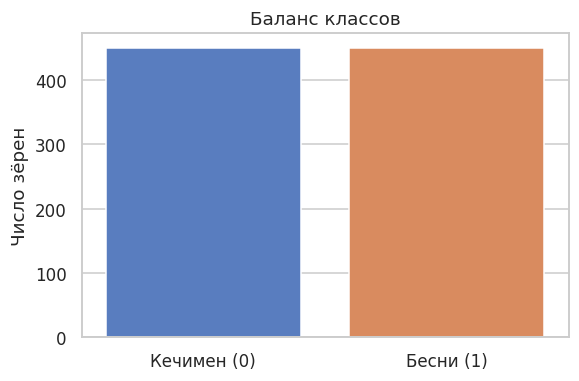

In [1]:
%matplotlib inline
import os
import time
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score

tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.autolayout"] = True

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

RU = {
    "Area": "Площадь",
    "MajorAxisLength": "Длина большой оси",
    "MinorAxisLength": "Длина малой оси",
    "Eccentricity": "Эксцентриситет",
    "ConvexArea": "Площадь оболочки",
    "Extent": "Заполненность",
    "Perimeter": "Периметр",
    "Class": "Бесни",
}
TARGET = "Бесни"
FEATURES = [name for key, name in RU.items() if key != "Class"]
LABELS = {0: "Кечимен (0)", 1: "Бесни (1)"}

df = pd.read_csv("data/raisin.csv")
df["Class"] = (df["Class"] == "Besni").astype(int)
df = df.rename(columns=RU)
print(f"Размерность: {df.shape[0]} x {df.shape[1]}")
print("Пропуски:", int(df.isnull().sum().sum()), "дубликаты:", int(df.duplicated().sum()))
print(df.dtypes.to_string())
df = df.drop_duplicates().reset_index(drop=True)
counts = df[TARGET].value_counts().rename(LABELS)
share = (df[TARGET].value_counts(normalize=True) * 100).rename(LABELS)
print(f"После очистки: {len(df)}")
print(pd.DataFrame({"Число": counts, "Доля, %": share.round(2)}).to_string())
fig, ax = plt.subplots(figsize=(5.4, 3.6))
sns.barplot(x=list(counts.index), y=counts.values, hue=list(counts.index), legend=False, ax=ax)
ax.set_ylabel("Число зёрен")
ax.set_xlabel("")
ax.set_title("Баланс классов")
plt.show()

### Вывод о данных

Пропусков и полных копий нет. Сорта поровну, по 450 зёрен, дополнительный oversampling не нужен. Стратификация сохраняет доли в фолдах. Признаки числовые. StandardScaler считается заново внутри каждого фолда, потому что площадь в десятках тысяч пикселей иначе задавит эксцентриситет.

### 3) Baseline

Отложенная выборка — 20%, `random_state=42`. Baseline — логистическая регрессия. Её accuracy на отложенной выборке является точкой отсчёта.

In [2]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=500, random_state=SEED)),
])
baseline.fit(X_train, y_train)
base_pred = baseline.predict(X_test)
base_proba = baseline.predict_proba(X_test)[:, 1]
baseline_accuracy = accuracy_score(y_test, base_pred)
print(f"Обучение {len(y_train)}, отложенная выборка {len(y_test)}")
print(f"Доля Бесни, train / test: {y_train.mean():.3f} / {y_test.mean():.3f}")
print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Baseline precision: {precision_score(y_test, base_pred, zero_division=0):.3f}")
print(f"Baseline recall: {recall_score(y_test, base_pred):.3f}")
print(f"Baseline F1: {f1_score(y_test, base_pred):.3f}")
print(f"Baseline AUC: {roc_auc_score(y_test, base_proba):.3f}")

Обучение 720, отложенная выборка 180
Доля Бесни, train / test: 0.500 / 0.500
Baseline accuracy: 0.922
Baseline precision: 0.942
Baseline recall: 0.900
Baseline F1: 0.920
Baseline AUC: 0.959


### 4) Пять фолдов и сетка

На обучающей части — стратифицированная 5-fold кросс-валидация. В каждом фолде масштаб считается только по четырём обучающим частям.

Сетка:

- скорость Adam: 0,01, 0,001 и 0,0001;
- архитектура A: один слой на 8 нейронов ReLU;
- архитектура B: слои 16 и 8;
- архитектура C: те же слои и Dropout 0,3 между ними.

Каждая конфигурация — многослойный перцептрон: полносвязные слои, 40 эпох, батч 16, бинарная кросс-энтропия, сигмоида на выходе. Критерий — средняя accuracy фолдов, при равенстве — меньший разброс. TensorBoard пишет accuracy и loss каждого фолда в `logs/extra`.

In [3]:
ARCHS = {
    "A: 8 relu": {"layers": (8,), "dropout": 0.0},
    "B: 16-8 relu": {"layers": (16, 8), "dropout": 0.0},
    "C: 16-dropout-8": {"layers": (16, 8), "dropout": 0.3},
}
LRS = [1e-2, 1e-3, 1e-4]
EPOCHS = 40
BATCH = 16
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_model(n_features, layers, dropout, lr):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(n_features,)))
    for index, units in enumerate(layers):
        model.add(tf.keras.layers.Dense(int(units), activation="relu"))
        if dropout and index < len(layers) - 1:
            model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy", metrics=["accuracy"])
    return model


rows, curves = [], {}
X_train_np = X_train.to_numpy(dtype=float)
y_train_np = y_train.to_numpy(dtype=int)
for arch_name, spec in ARCHS.items():
    for lr in LRS:
        tag = f"{arch_name}_lr{lr:.0e}".replace(" ", "_").replace(":", "")
        fold_acc, fold_loss, fold_f1, fold_time, fold_gap, val_curves = [], [], [], [], [], []
        for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train_np, y_train_np)):
            scaler = StandardScaler()
            x_tr = scaler.fit_transform(X_train_np[tr_idx])
            x_va = scaler.transform(X_train_np[va_idx])
            y_tr, y_va = y_train_np[tr_idx], y_train_np[va_idx]
            model = make_model(x_tr.shape[1], spec["layers"], spec["dropout"], lr)
            os.makedirs(f"logs/extra/{tag}/fold{fold}", exist_ok=True)
            started = time.perf_counter()
            history = model.fit(
                x_tr, y_tr, validation_data=(x_va, y_va), epochs=EPOCHS, batch_size=BATCH, verbose=0,
                callbacks=[tf.keras.callbacks.TensorBoard(log_dir=f"logs/extra/{tag}/fold{fold}", histogram_freq=0)],
            )
            elapsed = time.perf_counter() - started
            proba = model.predict(x_va, verbose=0).ravel()
            pred = (proba >= 0.5).astype(int)
            fold_acc.append(float(accuracy_score(y_va, pred)))
            fold_loss.append(float(history.history["val_loss"][-1]))
            fold_f1.append(float(f1_score(y_va, pred, zero_division=0)))
            fold_time.append(elapsed)
            fold_gap.append(float(history.history["accuracy"][-1]) - float(accuracy_score(y_va, pred)))
            val_curves.append(history.history["val_accuracy"])
        curves[(arch_name, lr)] = np.mean(np.vstack(val_curves), axis=0)
        rows.append({
            "Архитектура": arch_name,
            "Скорость": lr,
            "Accuracy, среднее": float(np.mean(fold_acc)),
            "Accuracy, ст. откл.": float(np.std(fold_acc, ddof=1)),
            "Loss, среднее": float(np.mean(fold_loss)),
            "F1, среднее": float(np.mean(fold_f1)),
            "Время фолда, с": float(np.mean(fold_time)),
            "Разрыв train-val": float(np.mean(fold_gap)),
        })
        print(f"{arch_name}, lr={lr:.0e}: acc {np.mean(fold_acc):.3f} ± {np.std(fold_acc, ddof=1):.3f}")

search = pd.DataFrame(rows).sort_values(
    ["Accuracy, среднее", "Accuracy, ст. откл."], ascending=[False, True]
).reset_index(drop=True)
print(search.round(3).to_string(index=False))
best = search.iloc[0]
print("Лучшая конфигурация:")
print(best.to_string())

A: 8 relu, lr=1e-02: acc 0.844 ± 0.040


A: 8 relu, lr=1e-03: acc 0.850 ± 0.044


A: 8 relu, lr=1e-04: acc 0.797 ± 0.035


B: 16-8 relu, lr=1e-02: acc 0.851 ± 0.044


B: 16-8 relu, lr=1e-03: acc 0.858 ± 0.042


B: 16-8 relu, lr=1e-04: acc 0.867 ± 0.043


C: 16-dropout-8, lr=1e-02: acc 0.847 ± 0.043


C: 16-dropout-8, lr=1e-03: acc 0.858 ± 0.051


C: 16-dropout-8, lr=1e-04: acc 0.850 ± 0.049
    Архитектура  Скорость  Accuracy, среднее  Accuracy, ст. откл.  Loss, среднее  F1, среднее  Время фолда, с  Разрыв train-val
   B: 16-8 relu     0.000              0.867                0.043          0.452        0.862           4.245            -0.007
   B: 16-8 relu     0.001              0.858                0.042          0.390        0.853           4.262             0.002
C: 16-dropout-8     0.001              0.858                0.051          0.455        0.850           4.329            -0.007
   B: 16-8 relu     0.010              0.851                0.044          0.489        0.844           4.232             0.028
      A: 8 relu     0.001              0.850                0.044          0.389        0.844           4.140             0.009
C: 16-dropout-8     0.000              0.850                0.049          0.528        0.850           4.410            -0.085
C: 16-dropout-8     0.010              0.847               

### 5) Кривые и сравнение конфигураций

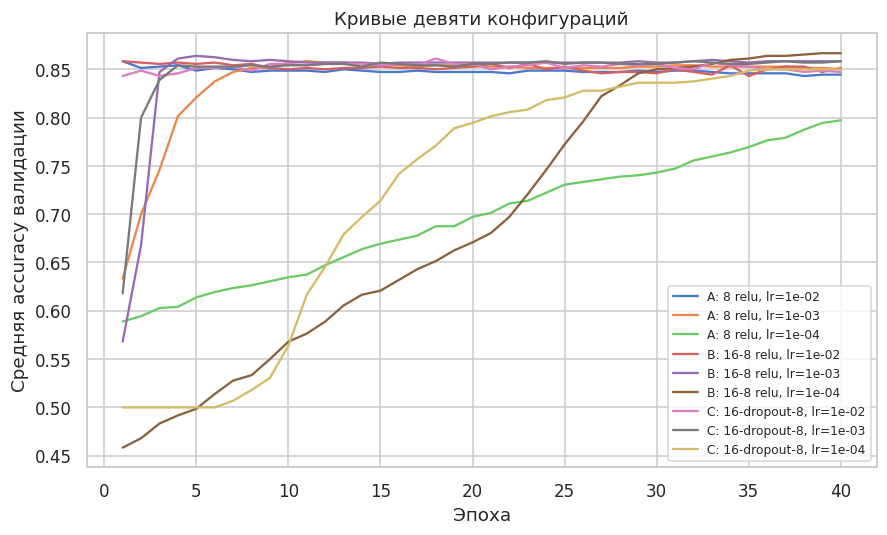

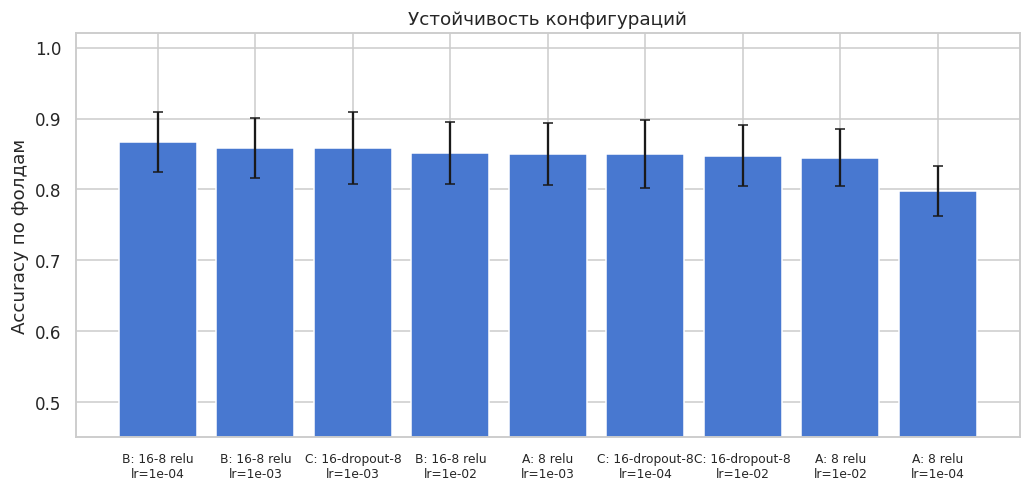

Средняя accuracy по скорости:
Скорость
0.0001    0.838
0.0010    0.856
0.0100    0.848
Разброс скоростей: 0.018
Средняя accuracy по архитектуре:
Архитектура
A: 8 relu          0.831
B: 16-8 relu       0.859
C: 16-dropout-8    0.852
Разброс архитектур: 0.028
Разрыв train-val лучшей: -0.007
Файлов TensorBoard: 90


In [4]:
fig, ax = plt.subplots(figsize=(8.2, 5.0))
for (arch_name, lr), curve in curves.items():
    ax.plot(np.arange(1, EPOCHS + 1), curve, label=f"{arch_name}, lr={lr:.0e}")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Средняя accuracy валидации")
ax.set_title("Кривые девяти конфигураций")
ax.legend(fontsize=8, loc="lower right")
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.6))
labels = [f"{arch}\nlr={lr:.0e}" for arch, lr in zip(search["Архитектура"], search["Скорость"])]
ax.bar(range(len(search)), search["Accuracy, среднее"], yerr=search["Accuracy, ст. откл."], capsize=3)
ax.set_xticks(range(len(search)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(0.45, 1.02)
ax.set_ylabel("Accuracy по фолдам")
ax.set_title("Устойчивость конфигураций")
plt.show()

by_lr = search.groupby("Скорость")["Accuracy, среднее"].mean()
by_arch = search.groupby("Архитектура")["Accuracy, среднее"].mean()
print("Средняя accuracy по скорости:")
print(by_lr.round(3).to_string())
print(f"Разброс скоростей: {by_lr.max() - by_lr.min():.3f}")
print("Средняя accuracy по архитектуре:")
print(by_arch.round(3).to_string())
print(f"Разброс архитектур: {by_arch.max() - by_arch.min():.3f}")
print(f"Разрыв train-val лучшей: {best['Разрыв train-val']:.3f}")
print("Файлов TensorBoard:", sum(len(files) for _, _, files in os.walk("logs/extra")))

### Пояснение к сетке

Лучшая ячейка сетки — архитектура **B** (слои 16 и 8, ReLU) при скорости **0,0001**: accuracy фолдов **0,867 ± 0,043**, средний F1 **0,862**, loss **0,452**, разрыв train−val **−0,007**. Валидация чуть выше обучения, переобучения нет.

По средним значениям архитектура сдвигает accuracy на **0,028** (A **0,831**, B **0,859**, C **0,852**), скорость — на **0,018**. Узкий перцептрон A при скорости 0,0001 остаётся на **0,797**: за 40 эпох маленький шаг не успевает. У B та же скорость уже лучшая. Dropout не обгоняет B. Время фолда около **4,2** с. В `logs/extra` лежит 90 файлов TensorBoard.

### 6) Финальная оценка

Лучшая конфигурация обучается на всей обучающей выборке. Accuracy сравнивается с логистической регрессией на тех же отложенных зёрнах.

In [5]:
spec = ARCHS[best["Архитектура"]]
lr = float(best["Скорость"])
scaler = StandardScaler()
x_tr = scaler.fit_transform(X_train_np)
x_te = scaler.transform(X_test.to_numpy(dtype=float))
final = make_model(x_tr.shape[1], spec["layers"], spec["dropout"], lr)
os.makedirs("logs/extra/final", exist_ok=True)
final.fit(
    x_tr, y_train_np, epochs=EPOCHS, batch_size=BATCH, verbose=0,
    callbacks=[tf.keras.callbacks.TensorBoard(log_dir="logs/extra/final", histogram_freq=0)],
)
proba = final.predict(x_te, verbose=0).ravel()
pred = (proba >= 0.5).astype(int)
final_accuracy = accuracy_score(y_test, pred)
final.summary()
print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Перцептрон accuracy: {final_accuracy:.3f}")
print(f"Разница: {final_accuracy - baseline_accuracy:+.3f}")
print(f"Перцептрон F1: {f1_score(y_test, pred):.3f}")
print(f"Перцептрон AUC: {roc_auc_score(y_test, proba):.3f}")
print(f"CV accuracy: {best['Accuracy, среднее']:.3f} ± {best['Accuracy, ст. откл.']:.3f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 821 (3.21 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 548 (2.14 KB)

Baseline accuracy: 0.922
Перцептрон accuracy: 0.922
Разница: +0.000
Перцептрон F1: 0.920
Перцептрон AUC: 0.955
CV accuracy: 0.867 ± 0.043


### 7) Заключение

Логистическая регрессия на 180 отложенных зёрнах даёт accuracy **0,922**, precision **0,942**, recall **0,900**, F1 **0,920** и AUC **0,959**.

Отобранный перцептрон B, скорость 0,0001, после обучения на всех 720 зёрнах повторяет эту точку: accuracy **0,922**, F1 **0,920**, AUC **0,955**. Разница с baseline равна **0,000**. Оценка по фолдам ниже, **0,867 ± 0,043**, потому что каждый фолд видит только четыре пятых обучающей части.

Перцептрон не поднимает качество выше линейной модели. Главный рычаг среди двух факторов — глубина: один слой на 8 нейронов отстаёт, Dropout почти ничего не добавляет. Accuracy не равна 1 ни у baseline, ни у перцептрона: сорта перекрываются по размеру.